# M6 benchmark visualization — Generator models

Comparison of 3 generators (`deepseek-v4-flash`, `ling-2.6-flash`, `gemini-3.5-flash-lite`) over **75 stratified golden queries** (25 short / 25 medium / 25 long, by expected-answer length using the EDA percentiles).

**Setup**: fixed retriever (voyage-4-lite, `vector_only`, k=10), judge `openai/gpt-5.6-luna`, metrics Correctness / Faithfulness / AnswerRelevancy + generation latency + output tokens (tiktoken).

Source: `evaluation_notebooks/raw_results/m6optc_<tag>_golden_se_75_estratificado_*.csv`

In [12]:
import csv, json, re
from pathlib import Path
from statistics import mean, median

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# ── Locate the project root (Tarea_2) by walking up from cwd ──
ROOT = Path.cwd()
for _ in range(5):
    if (ROOT / 'evaluation_notebooks').exists():
        break
    ROOT = ROOT.parent

RAW = ROOT / 'evaluation_notebooks' / 'raw_results'
GOLDEN75 = ROOT / 'evaluation_notebooks' / 'goldens' / 'golden_se_75_estratificado.json'

# ── OpenRouter prices ($/M tokens input, output) ──
PRICES = {
    'deepseek': (0.09, 0.18),
    'ling': (0.01, 0.03),
    'gemini': (0.30, 2.50),
}
INPUT_TOK_EST = 2000  # shared k=10 context (estimate)

def load_csv(path):
    return {r['ticketId']: r for r in csv.DictReader(open(path))}

def find_csv(tag):
    files = sorted(RAW.glob(f'm6optc_{tag}_golden_se_75_estratificado_*.csv'))
    if not files:
        raise FileNotFoundError(f'No CSV for {tag} in {RAW}')
    return load_csv(files[-1])

ds = find_csv('deepseek')
li = find_csv('ling')
ge = find_csv('gemini')
MODELS = {'deepseek': ds, 'ling': li, 'gemini': ge}

golden75 = {g['ticketId']: g['bucket'] for g in json.load(open(GOLDEN75))}

def f(x):
    return float(x) if x not in (None, '') else None

print('Root:', ROOT)
print('Models loaded:', {k: len(v) for k, v in MODELS.items()})
print('Buckets:', {b: sum(1 for t in golden75 if golden75[t] == b) for b in ['corto', 'medio', 'largo']})

Root: /home/guillermo/Documentos/Courses/GenAI_E2_bootcamp/Tarea_2
Models loaded: {'deepseek': 75, 'ling': 75, 'gemini': 75}
Buckets: {'corto': 25, 'medio': 25, 'largo': 25}


## 1. Correctness by bucket × model

The central story at a glance: deepseek wins at all three complexity levels, and the gap with ling grows on long answers.

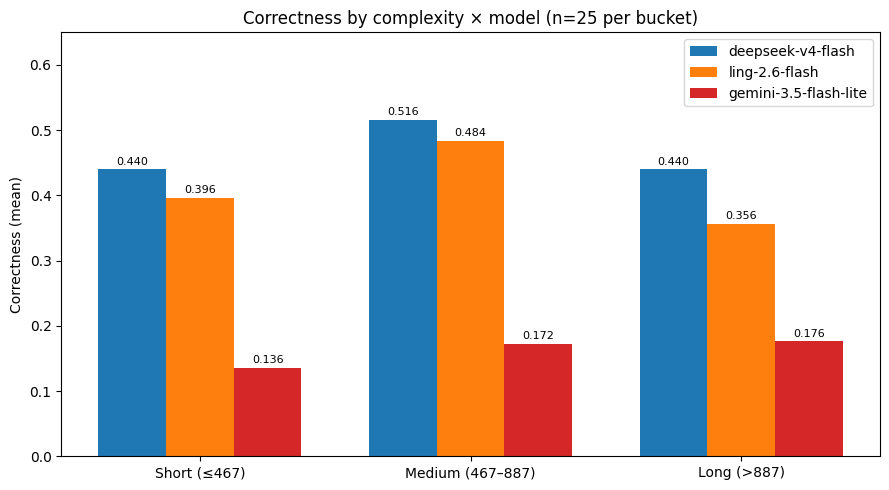

In [13]:
buckets = ['corto', 'medio', 'largo']
colors = {'deepseek': '#1f77b4', 'ling': '#ff7f0e', 'gemini': '#d62728'}
labels = {'deepseek': 'deepseek-v4-flash', 'ling': 'ling-2.6-flash', 'gemini': 'gemini-3.5-flash-lite'}

means = {m: [] for m in MODELS}
for b in buckets:
    tids = [t for t, bck in golden75.items() if bck == b]
    for m, d in MODELS.items():
        vals = [f(d[t]['correctness']) for t in tids if t in d]
        means[m].append(mean(vals))

x = np.arange(len(buckets))
w = 0.25

fig, ax = plt.subplots(figsize=(9, 5))
for i, m in enumerate(MODELS):
    bars = ax.bar(x + (i - 1) * w, means[m], w, label=labels[m], color=colors[m])
    ax.bar_label(bars, fmt='%.3f', padding=2, fontsize=8)

ax.set_xticks(x, ['Short (≤467)', 'Medium (467–887)', 'Long (>887)'])
ax.set_ylabel('Correctness (mean)')
ax.set_title('Correctness by complexity × model (n=25 per bucket)')
ax.legend()
ax.set_ylim(0, 0.65)
ax.axhline(0, color='black', lw=0.5)
plt.tight_layout()
plt.show()

## 2. Generation latency per model (boxplot, 75 queries each)

Shows deepseek's **tail**, which medians hide: P95 of 64s on the medium bucket and max values of 120s.

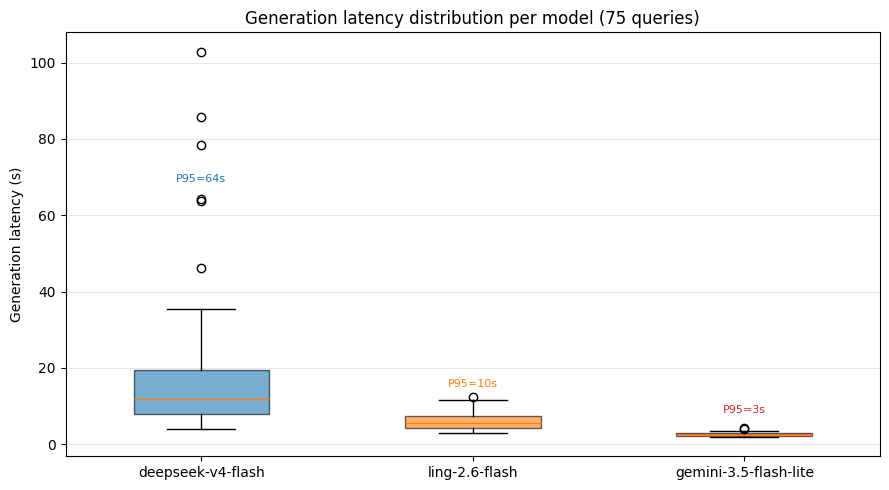

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
data = []
for m in MODELS:
    data.append([f(d['generation_secs']) for d in MODELS[m].values() if f(d['generation_secs']) is not None])

bp = ax.boxplot(data, tick_labels=[labels[m] for m in MODELS], patch_artist=True,
                showfliers=True, widths=0.5)
for patch, m in zip(bp['boxes'], MODELS):
    patch.set_facecolor(colors[m])
    patch.set_alpha(0.6)

ax.set_ylabel('Generation latency (s)')
ax.set_title('Generation latency distribution per model (75 queries)')
ax.grid(axis='y', alpha=0.3)

# Annotate P95
for i, m in enumerate(MODELS, 1):
    gs = sorted(data[i-1])
    p95 = gs[int(len(gs)*0.95)-1]
    ax.annotate(f'P95={p95:.0f}s', xy=(i, p95), xytext=(i, p95 + 5),
                ha='center', fontsize=8, color=colors[m])
plt.tight_layout()
plt.show()

## 3. Δ Correctness (ling − deepseek) by bucket

Visualizes "the loss grows with complexity": −4.4 → −3.2 → −8.4 points.

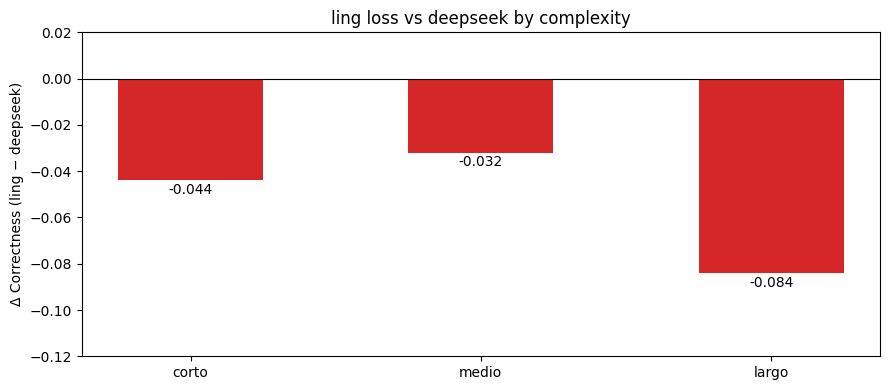

In [15]:
deltas = [means['ling'][i] - means['deepseek'][i] for i in range(3)]

fig, ax = plt.subplots(figsize=(9, 4))
colors_d = ['#2ca02c' if d > 0 else '#d62728' for d in deltas]
bars = ax.bar(buckets, deltas, color=colors_d, width=0.5)
ax.bar_label(bars, fmt='%+.3f', padding=2)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('Δ Correctness (ling − deepseek)')
ax.set_title('ling loss vs deepseek by complexity')
ax.set_ylim(-0.12, 0.02)
plt.tight_layout()
plt.show()

## 4. Cost per 1K queries (input/output split, log scale)

*Artificial Analysis* style (cost segmented by token type). Input is shared (~2K tokens estimated); output is what discriminates. Log scale so all 3 models are visible.

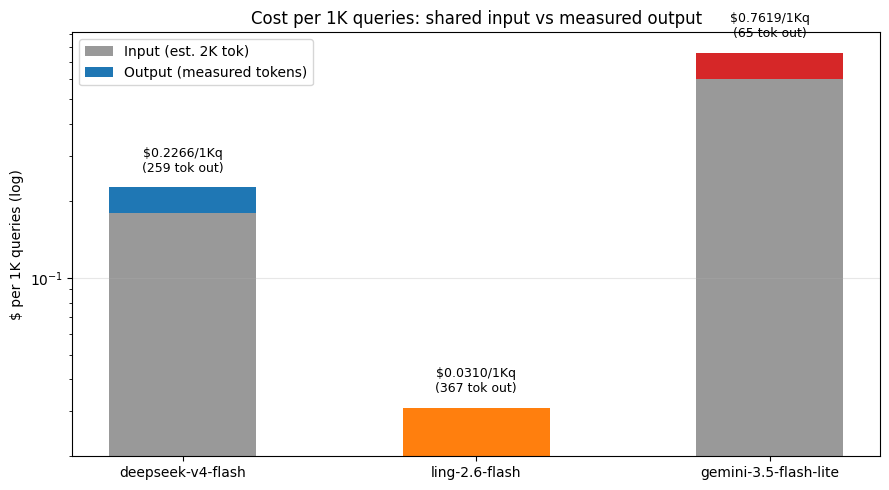

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))

models_list = list(MODELS)
x = np.arange(len(models_list))
inp_cost = [INPUT_TOK_EST * PRICES[m][0] / 1e6 * 1000 for m in models_list]
out_toks = [mean([f(d['output_tokens']) for d in MODELS[m].values() if f(d['output_tokens']) is not None]) for m in models_list]
out_cost = [out_toks[i] * PRICES[m][1] / 1e6 * 1000 for i, m in enumerate(models_list)]

b1 = ax.bar(x, inp_cost, 0.5, label='Input (est. 2K tok)', color='#999999')
b2 = ax.bar(x, out_cost, 0.5, bottom=inp_cost, label='Output (measured tokens)', color=[colors[m] for m in models_list])

tot = [i + o for i, o in zip(inp_cost, out_cost)]
for i, t in enumerate(tot):
    ax.text(i, t * 1.15, f'${t:.4f}/1Kq\n({out_toks[i]:.0f} tok out)', ha='center', fontsize=9)

ax.set_xticks(x, [labels[m] for m in models_list])
ax.set_yscale('log')
ax.set_ylabel('$ per 1K queries (log)')
ax.set_title('Cost per 1K queries: shared input vs measured output')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Quality vs cost scatter — with attractive quadrant and Pareto frontier

The signature *Artificial Analysis* chart (Intelligence vs Cost per Task). X-axis: cost per 1K queries (log). Y-axis: Correctness. **9 points** (3 models × 3 buckets).

The **upper-left quadrant** (low cost, high quality) is the "most attractive". The **Pareto frontier** connects the non-dominated points (where no other point has both better quality and lower cost).

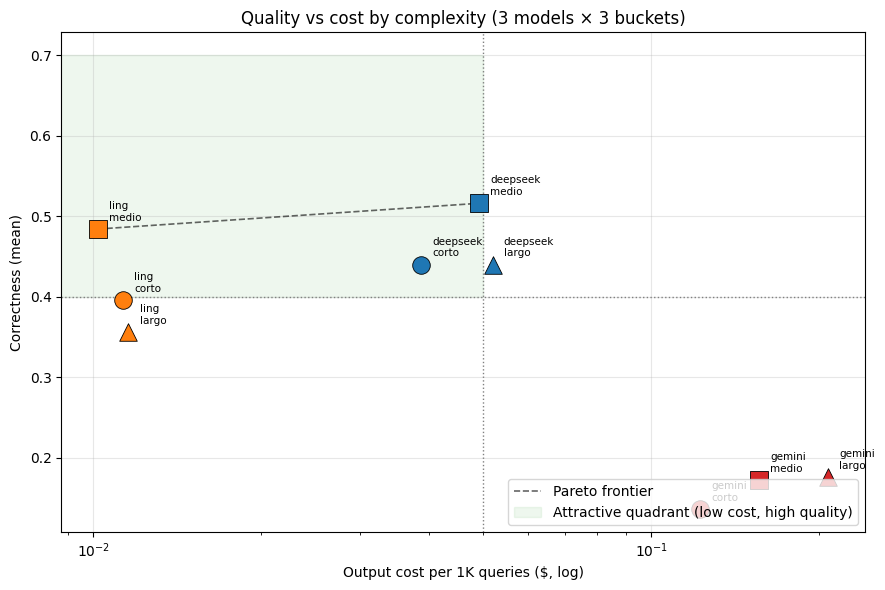

In [17]:
pts = []  # (cost_out_1k, correctness, model, bucket)
for b in buckets:
    tids = [t for t, bck in golden75.items() if bck == b]
    for m, d in MODELS.items():
        c = mean([f(d[t]['correctness']) for t in tids if t in d])
        toks = mean([f(d[t]['output_tokens']) for t in tids if t in d])
        cost = toks * PRICES[m][1] / 1e6 * 1000
        pts.append((cost, c, m, b))

markers = {'corto': 'o', 'medio': 's', 'largo': '^'}

fig, ax = plt.subplots(figsize=(9, 6))
for cost, c, m, b in pts:
    ax.scatter(cost, c, marker=markers[b], s=160, color=colors[m],
               edgecolor='black', linewidth=0.6, zorder=3)
    ax.annotate(f'{labels[m].split("-")[0]}\n{b}', (cost, c),
                textcoords='offset points', xytext=(8, 6), fontsize=7.5)

# Pareto frontier: non-dominated points (lower cost → highest quality so far)
sorted_pts = sorted(pts, key=lambda p: p[0])
pareto = []
best_c = -1
for cost, c, m, b in sorted_pts:
    if c > best_c:
        pareto.append((cost, c))
        best_c = c
if len(pareto) > 1:
    px_, py_ = zip(*pareto)
    ax.plot(px_, py_, 'k--', lw=1.2, alpha=0.6, label='Pareto frontier')

# Attractive quadrant shading (low cost + high quality)
ax.axvline(0.05, color='gray', ls=':', lw=1)
ax.axhline(0.4, color='gray', ls=':', lw=1)
ax.fill_between([0, 0.05], 0.4, 0.7, color='#2ca02c', alpha=0.08,
                label='Attractive quadrant (low cost, high quality)')

ax.set_xscale('log')
ax.set_xlabel('Output cost per 1K queries ($, log)')
ax.set_ylabel('Correctness (mean)')
ax.set_title('Quality vs cost by complexity (3 models × 3 buckets)')
ax.grid(alpha=0.3)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 6. Quality vs P95 latency scatter

The equivalent of *Intelligence vs Time per Task* from Artificial Analysis: how much quality do you buy for how much latency?

X-axis: P95 latency (the tail — what matters in production). Y-axis: Correctness. Point size: cost.

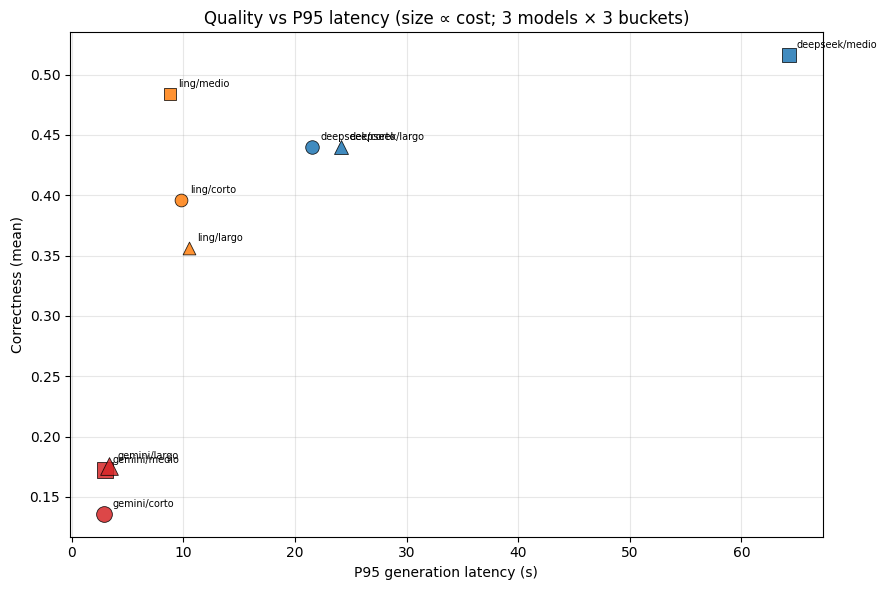

In [18]:
fig, ax = plt.subplots(figsize=(9, 6))
for b in buckets:
    tids = [t for t, bck in golden75.items() if bck == b]
    for m, d in MODELS.items():
        c = mean([f(d[t]['correctness']) for t in tids if t in d])
        gs = sorted([f(d[t]['generation_secs']) for t in tids if t in d])
        p95 = gs[int(len(gs)*0.95)-1]
        toks = mean([f(d[t]['output_tokens']) for t in tids if t in d])
        cost = toks * PRICES[m][1] / 1e6 * 1000
        ax.scatter(p95, c, marker=markers[b], s=80 + cost * 400, color=colors[m],
                   edgecolor='black', linewidth=0.6, alpha=0.85, zorder=3)
        ax.annotate(f'{labels[m].split("-")[0]}/{b}', (p95, c),
                    textcoords='offset points', xytext=(6, 5), fontsize=7)

ax.set_xlabel('P95 generation latency (s)')
ax.set_ylabel('Correctness (mean)')
ax.set_title('Quality vs P95 latency (size ∝ cost; 3 models × 3 buckets)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Latency vs output tokens scatter (per query, 225 points)

Three-dimensional trade-off at query level: ling is consistent and verbose; deepseek is spread out (long tail); gemini is terse and fast but poor.

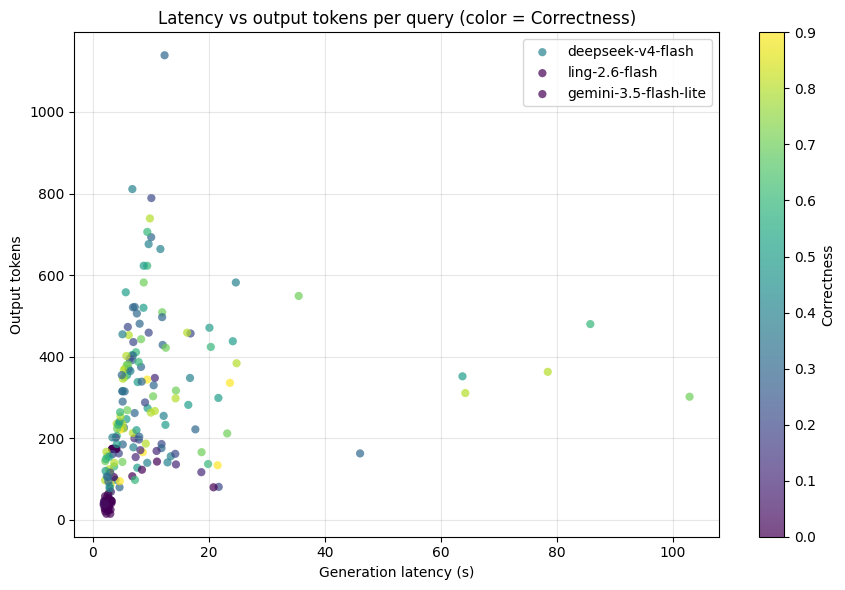

In [19]:
fig, ax = plt.subplots(figsize=(9, 6))
for m, d in MODELS.items():
    xs = [f(d[t]['generation_secs']) for t in d]
    ys = [f(d[t]['output_tokens']) for t in d]
    cs = [f(d[t]['correctness']) for t in d]
    sc = ax.scatter(xs, ys, c=cs, cmap='viridis', s=35, alpha=0.7,
                    edgecolor='none', label=labels[m])

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label('Correctness')
ax.set_xlabel('Generation latency (s)')
ax.set_ylabel('Output tokens')
ax.set_title('Latency vs output tokens per query (color = Correctness)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Export PNGs for the blog

Saves the figures into `documentation/markdowns/4_cost_optimization/img/` to reference them from the blog (charts 1-7 shown above are regenerated here to files).

In [20]:
IMG_DIR = ROOT / 'documentation' / 'markdowns' / '4_cost_optimization' / 'img'
IMG_DIR.mkdir(parents=True, exist_ok=True)

# Regenerate each figure to a file (cells above showed them on screen)
# 1. Correctness by bucket
fig, ax = plt.subplots(figsize=(9, 5))
for i, m in enumerate(MODELS):
    bars = ax.bar(x + (i - 1) * w, means[m], w, label=labels[m], color=colors[m])
    ax.bar_label(bars, fmt='%.3f', padding=2, fontsize=8)
ax.set_xticks(x, ['Short (≤467)', 'Medium (467–887)', 'Long (>887)'])
ax.set_ylabel('Correctness (mean)')
ax.set_title('Correctness by complexity × model (n=25 per bucket)')
ax.legend(); ax.set_ylim(0, 0.65)
plt.tight_layout(); plt.savefig(IMG_DIR / 'correctness_by_bucket.png', dpi=150); plt.close()

# 2. Latency boxplot
fig, ax = plt.subplots(figsize=(9, 5))
bp = ax.boxplot(data, tick_labels=[labels[m] for m in MODELS], patch_artist=True, showfliers=True, widths=0.5)
for patch, m in zip(bp['boxes'], MODELS):
    patch.set_facecolor(colors[m]); patch.set_alpha(0.6)
for i, m in enumerate(MODELS, 1):
    gs = sorted(data[i-1]); p95 = gs[int(len(gs)*0.95)-1]
    ax.annotate(f'P95={p95:.0f}s', xy=(i, p95), xytext=(i, p95 + 5), ha='center', fontsize=8, color=colors[m])
ax.set_ylabel('Generation latency (s)')
ax.set_title('Generation latency distribution per model (75 queries)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.savefig(IMG_DIR / 'latency_boxplot.png', dpi=150); plt.close()

# 3. Delta bars
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(buckets, deltas, color=['#d62728']*3, width=0.5)
ax.bar_label(bars, fmt='%+.3f', padding=2)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('Δ Correctness (ling − deepseek)')
ax.set_title('ling loss vs deepseek by complexity')
ax.set_ylim(-0.12, 0.02)
plt.tight_layout(); plt.savefig(IMG_DIR / 'delta_by_bucket.png', dpi=150); plt.close()

# 5. Quality vs cost scatter with Pareto
fig, ax = plt.subplots(figsize=(9, 6))
for cost, c, m, b in pts:
    ax.scatter(cost, c, marker=markers[b], s=160, color=colors[m], edgecolor='black', linewidth=0.6, zorder=3)
    ax.annotate(f'{labels[m].split("-")[0]}\n{b}', (cost, c), textcoords='offset points', xytext=(8, 6), fontsize=7.5)
if len(pareto) > 1:
    px_, py_ = zip(*pareto)
    ax.plot(px_, py_, 'k--', lw=1.2, alpha=0.6, label='Pareto frontier')
ax.axvline(0.05, color='gray', ls=':', lw=1); ax.axhline(0.4, color='gray', ls=':', lw=1)
ax.fill_between([0, 0.05], 0.4, 0.7, color='#2ca02c', alpha=0.08, label='Attractive quadrant')
ax.set_xscale('log')
ax.set_xlabel('Output cost per 1K queries ($, log)')
ax.set_ylabel('Correctness (mean)')
ax.set_title('Quality vs cost by complexity (3 models × 3 buckets)')
ax.grid(alpha=0.3); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(IMG_DIR / 'quality_vs_cost_pareto.png', dpi=150); plt.close()

# 6. Quality vs P95 latency
fig, ax = plt.subplots(figsize=(9, 6))
for b in buckets:
    tids = [t for t, bck in golden75.items() if bck == b]
    for m, d in MODELS.items():
        c = mean([f(d[t]['correctness']) for t in tids if t in d])
        gs = sorted([f(d[t]['generation_secs']) for t in tids if t in d])
        p95 = gs[int(len(gs)*0.95)-1]
        toks = mean([f(d[t]['output_tokens']) for t in tids if t in d])
        cost = toks * PRICES[m][1] / 1e6 * 1000
        ax.scatter(p95, c, marker=markers[b], s=80 + cost * 400, color=colors[m], edgecolor='black', linewidth=0.6, alpha=0.85, zorder=3)
        ax.annotate(f'{labels[m].split("-")[0]}/{b}', (p95, c), textcoords='offset points', xytext=(6, 5), fontsize=7)
ax.set_xlabel('P95 generation latency (s)')
ax.set_ylabel('Correctness (mean)')
ax.set_title('Quality vs P95 latency (size ∝ cost; 3 models × 3 buckets)')
ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(IMG_DIR / 'quality_vs_latency.png', dpi=150); plt.close()

# 7. Latency vs tokens per query
fig, ax = plt.subplots(figsize=(9, 6))
for m, d in MODELS.items():
    xs = [f(d[t]['generation_secs']) for t in d]
    ys = [f(d[t]['output_tokens']) for t in d]
    cs = [f(d[t]['correctness']) for t in d]
    sc = ax.scatter(xs, ys, c=cs, cmap='viridis', s=35, alpha=0.7, edgecolor='none', label=labels[m])
cbar = fig.colorbar(sc, ax=ax); cbar.set_label('Correctness')
ax.set_xlabel('Generation latency (s)')
ax.set_ylabel('Output tokens')
ax.set_title('Latency vs output tokens per query (color = Correctness)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(IMG_DIR / 'latency_vs_tokens_scatter.png', dpi=150); plt.close()

print('PNGs saved to:', IMG_DIR)
for p in sorted(IMG_DIR.glob('*.png')):
    print(' -', p.name)

PNGs saved to: /home/guillermo/Documentos/Courses/GenAI_E2_bootcamp/Tarea_2/documentation/markdowns/4_cost_optimization/img
 - correctness_by_bucket.png
 - delta_by_bucket.png
 - latency_boxplot.png
 - latency_vs_tokens_scatter.png
 - quality_vs_cost_pareto.png
 - quality_vs_latency.png
